# Projeto de Machine Learning


In [ ]:
import kagglehub
import pandas as pd
import os

# Baixa a versão mais recente (retorna o caminho da PASTA)
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")

print("Path to dataset files:", path)

# Monta o caminho completo até o arquivo CSV
arquivo_csv = os.path.join(path, "healthcare-dataset-stroke-data.csv")

# Cria a variável 'dataset' com o conteúdo do CSV
dataset = pd.read_csv(arquivo_csv)

# Confere que carregou certo
print(dataset.head())

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/stroke-prediction-dataset
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     ne

In [ ]:
# Só as colunas numéricas (int e float)
colunas_numericas = dataset.select_dtypes(include=["number"])

# Só as colunas NÃO numéricas (texto/categóricas)
colunas_nao_numericas = dataset.select_dtypes(exclude=["number"])


In [ ]:
print(dataset.isnull().sum())


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [ ]:
print(colunas_numericas.head())

      id   age  hypertension  heart_disease  avg_glucose_level   bmi  stroke
0   9046  67.0             0              1             228.69  36.6       1
1  51676  61.0             0              0             202.21   NaN       1
2  31112  80.0             0              1             105.92  32.5       1
3  60182  49.0             0              0             171.23  34.4       1
4   1665  79.0             1              0             174.12  24.0       1


In [ ]:
print(colunas_nao_numericas.head())

   gender ever_married      work_type Residence_type   smoking_status
0    Male          Yes        Private          Urban  formerly smoked
1  Female          Yes  Self-employed          Rural     never smoked
2    Male          Yes        Private          Rural     never smoked
3  Female          Yes        Private          Urban           smokes
4  Female          Yes  Self-employed          Rural     never smoked


In [ ]:
# Mostra nome de cada coluna, quantos valores únicos tem, e exemplos de valores
for coluna in dataset.columns:
    print(f"Coluna: {coluna}")
    print(f"  Tipo: {dataset[coluna].dtype}")
    print(f"  Valores únicos: {dataset[coluna].nunique()}")
    print(f"  Exemplos: {dataset[coluna].unique()[:5]}")
    print()

Coluna: id
  Tipo: int64
  Valores únicos: 5110
  Exemplos: [ 9046 51676 31112 60182  1665]

Coluna: gender
  Tipo: object
  Valores únicos: 3
  Exemplos: ['Male' 'Female' 'Other']

Coluna: age
  Tipo: float64
  Valores únicos: 104
  Exemplos: [67. 61. 80. 49. 79.]

Coluna: hypertension
  Tipo: int64
  Valores únicos: 2
  Exemplos: [0 1]

Coluna: heart_disease
  Tipo: int64
  Valores únicos: 2
  Exemplos: [1 0]

Coluna: ever_married
  Tipo: object
  Valores únicos: 2
  Exemplos: ['Yes' 'No']

Coluna: work_type
  Tipo: object
  Valores únicos: 5
  Exemplos: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']

Coluna: Residence_type
  Tipo: object
  Valores únicos: 2
  Exemplos: ['Urban' 'Rural']

Coluna: avg_glucose_level
  Tipo: float64
  Valores únicos: 3979
  Exemplos: [228.69 202.21 105.92 171.23 174.12]

Coluna: bmi
  Tipo: float64
  Valores únicos: 418
  Exemplos: [36.6  nan 32.5 34.4 24. ]

Coluna: smoking_status
  Tipo: object
  Valores únicos: 4
  Exemplos: ['forme

In [ ]:
# Conta valores ausentes (NaN) por coluna
print("Valores ausentes por coluna:")
print(dataset.isnull().sum())

# Mostra a porcentagem de ausentes por coluna (mais fácil de interpretar)
print("\nPorcentagem de ausentes por coluna:")
print((dataset.isnull().sum() / len(dataset) * 100).round(2))

Valores ausentes por coluna:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Porcentagem de ausentes por coluna:
id                   0.00
gender               0.00
age                  0.00
hypertension         0.00
heart_disease        0.00
ever_married         0.00
work_type            0.00
Residence_type       0.00
avg_glucose_level    0.00
bmi                  3.93
smoking_status       0.00
stroke               0.00
dtype: float64


In [ ]:
# .shape devolve uma tupla (número de linhas, número de colunas)
print("Formato do dataset:", dataset.shape)
print("Número de instâncias (linhas):", dataset.shape[0])
print("Número de features (colunas):", dataset.shape[1])

Formato do dataset: (5110, 12)
Número de instâncias (linhas): 5110
Número de features (colunas): 12


In [ ]:
# Visão geral: tipo de cada coluna + contagem de não-nulos, tudo de uma vez
dataset.info()

# Separando explicitamente pelos tipos (usando o select_dtypes que já vimos)
colunas_numericas = dataset.select_dtypes(include=["number"]).columns.tolist()
colunas_categoricas = dataset.select_dtypes(exclude=["number"]).columns.tolist()


# Nas categóricas: ver todos os valores possíveis, procurando categorias estranhas
for coluna in colunas_categoricas:
    print(f"{coluna}: {dataset[coluna].unique()}")

# Nas numéricas: estatísticas (min, max, média) pra achar valores impossíveis
print(dataset.describe())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB
gender: ['Male' 'Female' 'Other']
ever_married: ['Yes' 'No']
work_type: ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type: ['Ur

In [ ]:
# Contagem absoluta de cada classe na variável alvo
print("Contagem por classe (stroke):")
print(dataset["stroke"].value_counts())

# Proporção percentual de cada classe
print("\nProporção por classe (%):")
print((dataset["stroke"].value_counts(normalize=True) * 100).round(2))

Contagem por classe (stroke):
stroke
0    4861
1     249
Name: count, dtype: int64

Proporção por classe (%):
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


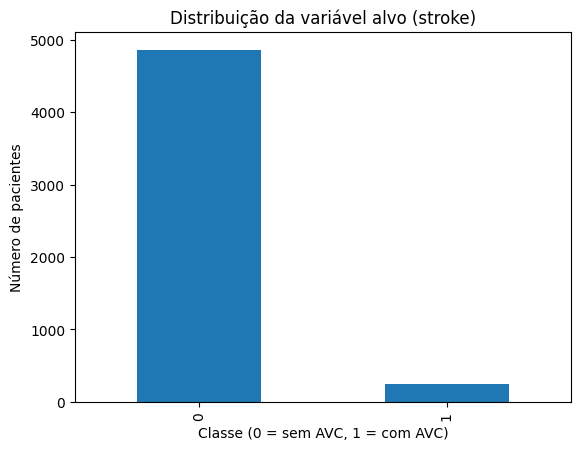

In [ ]:
import matplotlib.pyplot as plt

dataset["stroke"].value_counts().plot(kind="bar")
plt.title("Distribuição da variável alvo (stroke)")
plt.xlabel("Classe (0 = sem AVC, 1 = com AVC)")
plt.ylabel("Número de pacientes")
plt.show()

In [ ]:
# Conta a incidência de 'Unknown' na coluna 'smoking_status'
unknown_smoking = dataset['smoking_status'].value_counts().get('Unknown', 0)
print(f"Número de 'Unknown' em smoking_status: {unknown_smoking}")

# Conta a incidência de 'Other' na coluna 'gender'
other_gender = dataset['gender'].value_counts().get('Other', 0)
print(f"Número de 'Other' em gender: {other_gender}")

Número de 'Unknown' em smoking_status: 1544
Número de 'Other' em gender: 1


### Verificando Valores Nulos (NaN) e `None`

Conforme já vimos, o método `.isnull().sum()` é a forma padrão de verificar a quantidade de valores `NaN` (Not a Number) em cada coluna de um DataFrame do pandas.

In [ ]:
# Verificando valores NaN (Not a Number)
print('Contagem de valores NaN por coluna:')
display(dataset.isnull().sum())

Contagem de valores NaN por coluna:


,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


É importante notar que, em DataFrames do pandas, valores `None` (do Python) em colunas numéricas são geralmente convertidos para `NaN` automaticamente. Em colunas de tipo `object` (que contêm strings ou objetos diversos), `None` pode permanecer como `None`. Podemos verificar explicitamente por `None` se necessário, embora seja menos comum após a leitura de dados típicos.

In [ ]:
# Verificando explicitamente por valores None em colunas do tipo 'object'
# (Pandas geralmente converte None para NaN em colunas numéricas)

print('\nContagem de valores None por coluna (apenas para colunas \'object\'):')
none_counts = {}
for col in dataset.select_dtypes(include='object').columns:
    none_counts[col] = (dataset[col] == None).sum()
display(pd.Series(none_counts))


Contagem de valores None por coluna (apenas para colunas 'object'):


,0
gender,0
ever_married,0
work_type,0
Residence_type,0
smoking_status,0


### Verificando Valores Zero

Agora, vamos verificar a presença de valores zero em cada coluna, pois em alguns contextos, zero pode ser considerado um valor 'ausente' ou atípico, dependendo do significado da coluna.

In [ ]:
# Contagem de valores zero por coluna
print('\nContagem de valores zero por coluna:')
zero_counts = {}
for col in dataset.columns:
    # Para evitar erros com colunas de texto, verificamos apenas onde o tipo é numérico
    if pd.api.types.is_numeric_dtype(dataset[col]):
        zero_counts[col] = (dataset[col] == 0).sum()
    else:
        zero_counts[col] = 'Não aplicável (coluna não numérica)'
display(pd.Series(zero_counts))


Contagem de valores zero por coluna:


,0
id,0
gender,Não aplicável (coluna não numérica)
age,0
hypertension,4612
heart_disease,4834
ever_married,Não aplicável (coluna não numérica)
work_type,Não aplicável (coluna não numérica)
Residence_type,Não aplicável (coluna não numérica)
avg_glucose_level,0
bmi,0


In [ ]:
# Filtrando o dataset para mostrar linhas onde 'bmi' é igual a zero
bmi_zero_df = dataset[dataset['bmi'] == 0]

print("Linhas onde 'bmi' é zero (primeiras 10):")
display(bmi_zero_df.head(10))

Linhas onde 'bmi' é zero (primeiras 10):


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke


In [ ]:
# Filtrando o dataset para mostrar linhas onde 'bmi' é NaN (nulo)
bmi_nan_df = dataset[dataset['bmi'].isnull()]

print("Linhas onde 'bmi' é NaN (primeiras 10):")
display(bmi_nan_df.head(10))

Linhas onde 'bmi' é NaN (primeiras 10):


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
8,27419,Female,59.0,0,0,Yes,Private,Rural,76.15,NaN,Unknown,1
13,8213,Male,78.0,0,1,Yes,Private,Urban,219.84,NaN,Unknown,1
19,25226,Male,57.0,0,1,No,Govt_job,Urban,217.08,NaN,Unknown,1
27,61843,Male,58.0,0,0,Yes,Private,Rural,189.84,NaN,Unknown,1
29,69160,Male,59.0,0,0,Yes,Private,Rural,211.78,NaN,formerly smoked,1
43,1845,Female,63.0,0,0,Yes,Private,Urban,90.90,NaN,formerly smoked,1
46,37937,Female,75.0,0,1,No,Self-employed,Urban,109.78,NaN,Unknown,1
50,18587,Female,76.0,0,0,No,Private,Urban,89.96,NaN,Unknown,1
51,15102,Male,78.0,1,0,Yes,Private,Urban,75.32,NaN,formerly smoked,1


### Verificando Consistência dos Dados

Vamos agora verificar se há valores nas colunas numéricas que estão fora de um range considerado válido, indicando possíveis erros na coleta ou registro dos dados.

#### Consistência da Coluna `age`

Vamos verificar idades abaixo de 0 ou acima de 121 anos (um limite comum para a idade humana).

In [ ]:
# Verificando 'age' fora da faixa (abaixo de 0 ou acima de 121)
inconsistent_age = dataset[(dataset['age'] < 0) | (dataset['age'] > 121)]

print("Linhas com 'age' inconsistente:")
if not inconsistent_age.empty:
    display(inconsistent_age)
else:
    print("Nenhuma idade inconsistente encontrada.")

Linhas com 'age' inconsistente:
Nenhuma idade inconsistente encontrada.


#### Consistência da Coluna `avg_glucose_level`

Para `avg_glucose_level`, consideraremos valores fora da faixa de 30 mg/dL (hipoglicemia severa) a 600 mg/dL (hiperglicemia severa) como potencialmente inconsistentes, embora limites clínicos específicos possam variar.

In [ ]:
# Verificando 'avg_glucose_level' fora da faixa (ex: < 30 ou > 600)
inconsistent_glucose = dataset[(dataset['avg_glucose_level'] < 30) | (dataset['avg_glucose_level'] > 600)]

print("Linhas com 'avg_glucose_level' inconsistente:")
if not inconsistent_glucose.empty:
    display(inconsistent_glucose)
else:
    print("Nenhum nível de glicose inconsistente encontrado.")

Linhas com 'avg_glucose_level' inconsistente:
Nenhum nível de glicose inconsistente encontrado.


#### Consistência da Coluna `bmi`

Para `bmi`, vamos verificar valores abaixo de 10 (considerado subnutrição extrema) ou acima de 80 (obesidade mórbida extrema), que são raros na população geral.

In [ ]:
# Verificando 'bmi' fora da faixa (ex: < 10 ou > 80)
inconsistent_bmi = dataset[(dataset['bmi'] < 10) | (dataset['bmi'] > 80)]

print("Linhas com 'bmi' inconsistente:")
if not inconsistent_bmi.empty:
    display(inconsistent_bmi)
else:
    print("Nenhum BMI inconsistente encontrado.")

Linhas com 'bmi' inconsistente:


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2128,56420,Male,17.0,1,0,No,Private,Rural,61.67,97.6,Unknown,0
4209,51856,Male,38.0,1,0,Yes,Private,Rural,56.90,92.0,never smoked,0


### Contagem de Incidências para Colunas Categóricas

Vamos agora verificar a distribuição de cada categoria nas colunas não numéricas para identificar desbalanceamentos ou categorias com poucos exemplos.

In [ ]:
print("Contagem de incidências por categoria nas colunas categóricas:\n")
for coluna in colunas_categoricas:
    print(f"Coluna: {coluna}")
    display(dataset[coluna].value_counts())
    print("\n" + "-" * 50 + "\n")

Contagem de incidências por categoria nas colunas categóricas:

Coluna: gender


,count
gender,
Female,2994
Male,2115
Other,1



--------------------------------------------------

Coluna: ever_married


,count
ever_married,
Yes,3353
No,1757



--------------------------------------------------

Coluna: work_type


,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22



--------------------------------------------------

Coluna: Residence_type


,count
Residence_type,
Urban,2596
Rural,2514



--------------------------------------------------

Coluna: smoking_status


,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789



--------------------------------------------------



### Contagem de Zeros e Uns em Colunas Numéricas

Agora vamos verificar a contagem de 0s e 1s nas colunas numéricas que geralmente representam categorias binárias ou a variável alvo (`stroke`), para entender o balanceamento desses valores.

In [ ]:
print("Contagem de Zeros e Uns por Coluna (numéricas binárias):\n")

# Filtra as colunas que são numéricas e que contêm apenas 0 e 1 (ou predominantemente)
# Excluímos 'id' e 'age' e 'avg_glucose_level' e 'bmi' pois são contínuas ou IDs
binary_numeric_columns = ['hypertension', 'heart_disease', 'stroke']

for coluna in binary_numeric_columns:
    print(f"Coluna: {coluna}")
    zero_count = (dataset[coluna] == 0).sum()
    one_count = (dataset[coluna] == 1).sum()

    print(f"  Contagem de 0: {zero_count}")
    print(f"  Contagem de 1: {one_count}")

    # Calcula a porcentagem
    total_count = zero_count + one_count
    if total_count > 0:
        zero_percent = (zero_count / total_count) * 100
        one_percent = (one_count / total_count) * 100
        print(f"  Porcentagem de 0: {zero_percent:.2f}%")
        print(f"  Porcentagem de 1: {one_percent:.2f}%")
    else:
        print("  (Não há valores 0 ou 1 nesta coluna)")
    print("\n" + "-" * 50 + "\n")


Contagem de Zeros e Uns por Coluna (numéricas binárias):

Coluna: hypertension
  Contagem de 0: 4612
  Contagem de 1: 498
  Porcentagem de 0: 90.25%
  Porcentagem de 1: 9.75%

--------------------------------------------------

Coluna: heart_disease
  Contagem de 0: 4834
  Contagem de 1: 276
  Porcentagem de 0: 94.60%
  Porcentagem de 1: 5.40%

--------------------------------------------------

Coluna: stroke
  Contagem de 0: 4861
  Contagem de 1: 249
  Porcentagem de 0: 95.13%
  Porcentagem de 1: 4.87%

--------------------------------------------------



In [ ]:
# Seleciona só as colunas numéricas
numericas = dataset.select_dtypes(include="number")

# Monta uma tabela com as três estatísticas pedidas, uma coluna cada
estatisticas = pd.DataFrame({
    "média": numericas.mean(),
    "mediana": numericas.median(),
    "desvio_padrão": numericas.std()
})

print(estatisticas.round(2))

                      média   mediana  desvio_padrão
id                 36517.83  36932.00       21161.72
age                   43.23     45.00          22.61
hypertension           0.10      0.00           0.30
heart_disease          0.05      0.00           0.23
avg_glucose_level    106.15     91.88          45.28
bmi                   28.89     28.10           7.85
stroke                 0.05      0.00           0.22


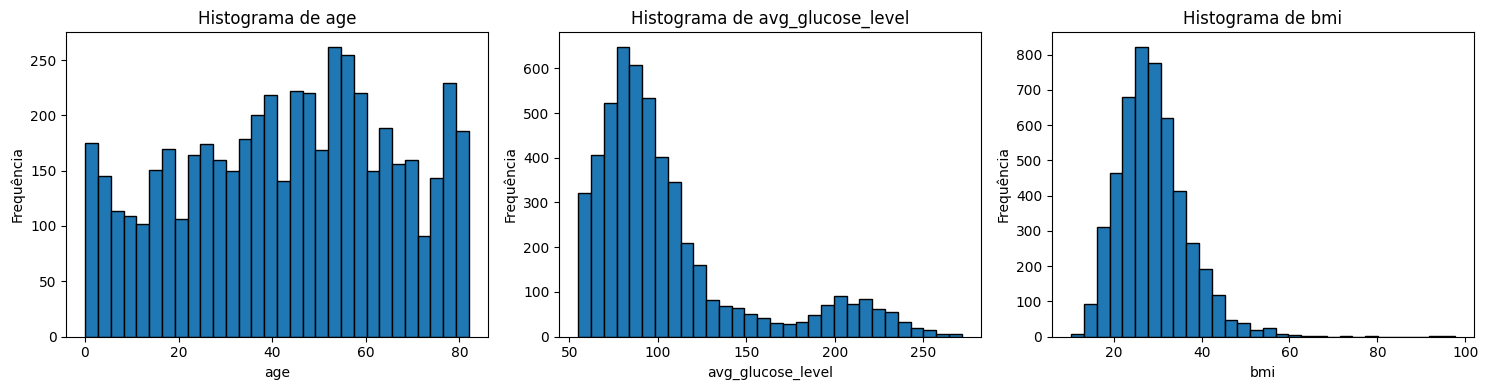

In [ ]:
import matplotlib.pyplot as plt

variaveis_continuas = ["age", "avg_glucose_level", "bmi"]

# Cria uma figura com 3 gráficos lado a lado (1 linha, 3 colunas)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, coluna in enumerate(variaveis_continuas):
    axes[i].hist(dataset[coluna].dropna(), bins=30, edgecolor="black")
    axes[i].set_title(f"Histograma de {coluna}")
    axes[i].set_xlabel(coluna)
    axes[i].set_ylabel("Frequência")

plt.tight_layout()
plt.show()

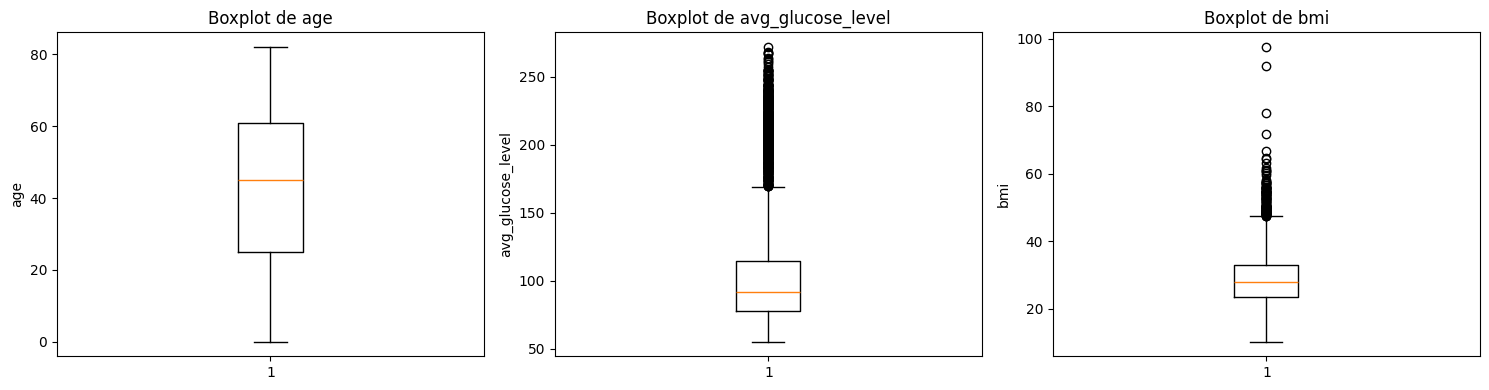

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, coluna in enumerate(variaveis_continuas):
    axes[i].boxplot(dataset[coluna].dropna())
    axes[i].set_title(f"Boxplot de {coluna}")
    axes[i].set_ylabel(coluna)

plt.tight_layout()
plt.show()

In [ ]:
for coluna in colunas_categoricas:
    print(f"\n=== {coluna} ===")
    print("Contagem:")
    print(dataset[coluna].value_counts())
    print("\nPorcentagem (%):")
    print((dataset[coluna].value_counts(normalize=True) * 100).round(2))


=== gender ===
Contagem:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Porcentagem (%):
gender
Female    58.59
Male      41.39
Other      0.02
Name: proportion, dtype: float64

=== ever_married ===
Contagem:
ever_married
Yes    3353
No     1757
Name: count, dtype: int64

Porcentagem (%):
ever_married
Yes    65.62
No     34.38
Name: proportion, dtype: float64

=== work_type ===
Contagem:
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Porcentagem (%):
work_type
Private          57.24
Self-employed    16.03
children         13.44
Govt_job         12.86
Never_worked      0.43
Name: proportion, dtype: float64

=== Residence_type ===
Contagem:
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

Porcentagem (%):
Residence_type
Urban    50.8
Rural    49.2
Name: proportion, dtype: float64

=== smoking_status ===
Contagem:
smoking_status
never sm

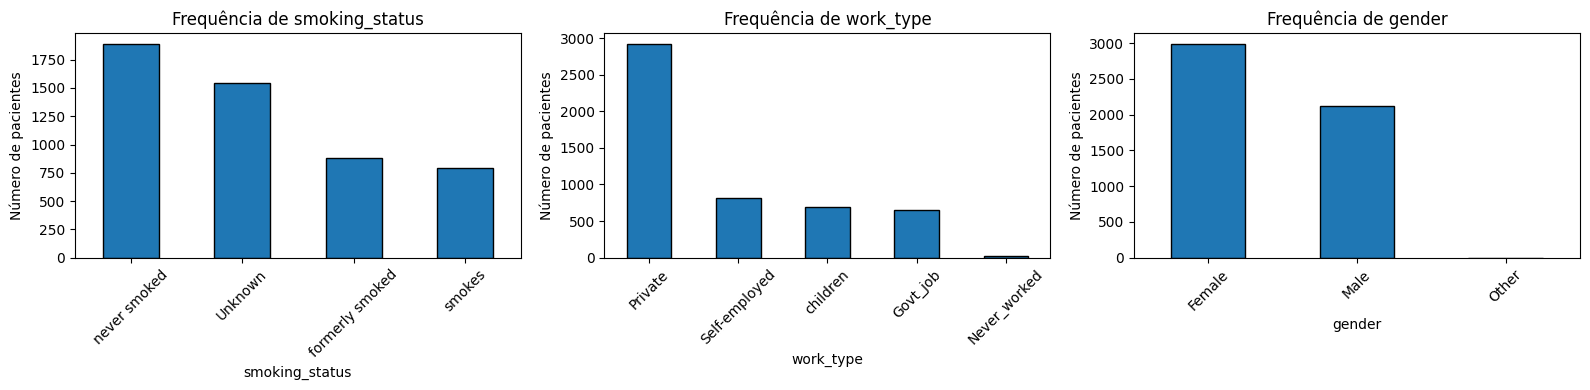

In [ ]:
categoricas_grafico = ["smoking_status", "work_type", "gender"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, coluna in enumerate(categoricas_grafico):
    dataset[coluna].value_counts().plot(kind="bar", ax=axes[i], edgecolor="black")
    axes[i].set_title(f"Frequência de {coluna}")
    axes[i].set_xlabel(coluna)
    axes[i].set_ylabel("Número de pacientes")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

### Resolvendo `NameError`: Recarregando Dados

O erro `NameError` indica que o notebook pode ter sido executado fora de ordem ou o kernel foi reiniciado, fazendo com que as variáveis `dataset`, `colunas_numericas` e `colunas_categoricas` não estivessem definidas. Esta célula recarregará os dados e redefinirá essas variáveis essenciais para que as etapas subsequentes possam ser executadas.

In [ ]:
import kagglehub
import pandas as pd
import os

# Recarrega o dataset para garantir que esteja definido
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
arquivo_csv = os.path.join(path, "healthcare-dataset-stroke-data.csv")
dataset = pd.read_csv(arquivo_csv)

# Redefine as listas de colunas numéricas e categóricas
colunas_numericas = dataset.select_dtypes(include=["number"]).columns.tolist()
colunas_categoricas = dataset.select_dtypes(exclude=["number"]).columns.tolist()

print("Dataset e listas de colunas recarregados com sucesso.")

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Dataset e listas de colunas recarregados com sucesso.


In [ ]:
from sklearn.model_selection import train_test_split

# Remove id (identificador, sem valor preditivo) e separa target
X = dataset.drop(columns=['id', 'stroke'])
y = dataset['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y            # mantém ~5% de AVC em treino e teste
)

print('Treino:', X_train.shape, '| % AVC:', round(y_train.mean()*100, 2))
print('Teste :', X_test.shape,  '| % AVC:', round(y_test.mean()*100, 2))

Treino: (4088, 10) | % AVC: 4.87
Teste : (1022, 10) | % AVC: 4.89


In [ ]:
train = X_train.copy()
train['stroke'] = y_train.values

num_cols = train.select_dtypes(include='number').columns.drop('stroke').tolist()
cat_cols = train.select_dtypes(exclude='number').columns.tolist()

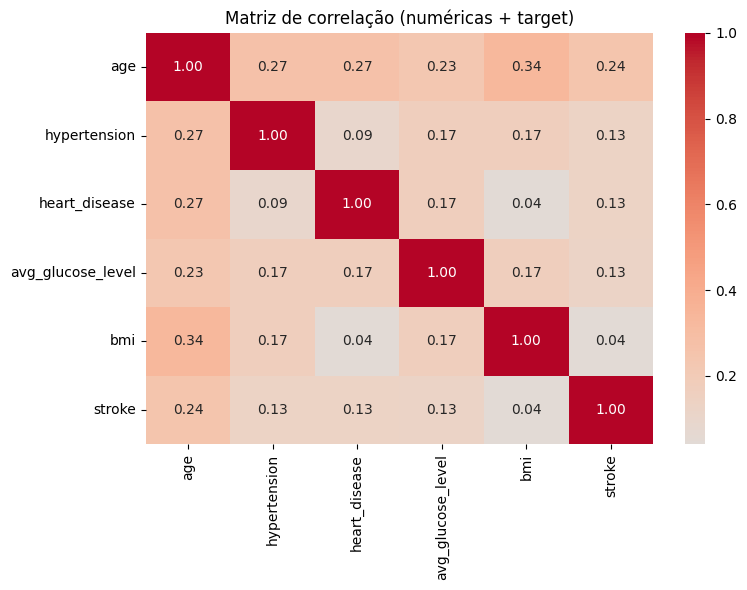

Correlação de cada numérica com stroke:
stroke               1.000
age                  0.243
hypertension         0.133
heart_disease        0.127
avg_glucose_level    0.125
bmi                  0.044
Name: stroke, dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(train[num_cols + ['stroke']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação (numéricas + target)')
plt.tight_layout()
plt.show()

print('Correlação de cada numérica com stroke:')
print(train[num_cols + ['stroke']].corr()['stroke']
      .sort_values(ascending=False).round(3))

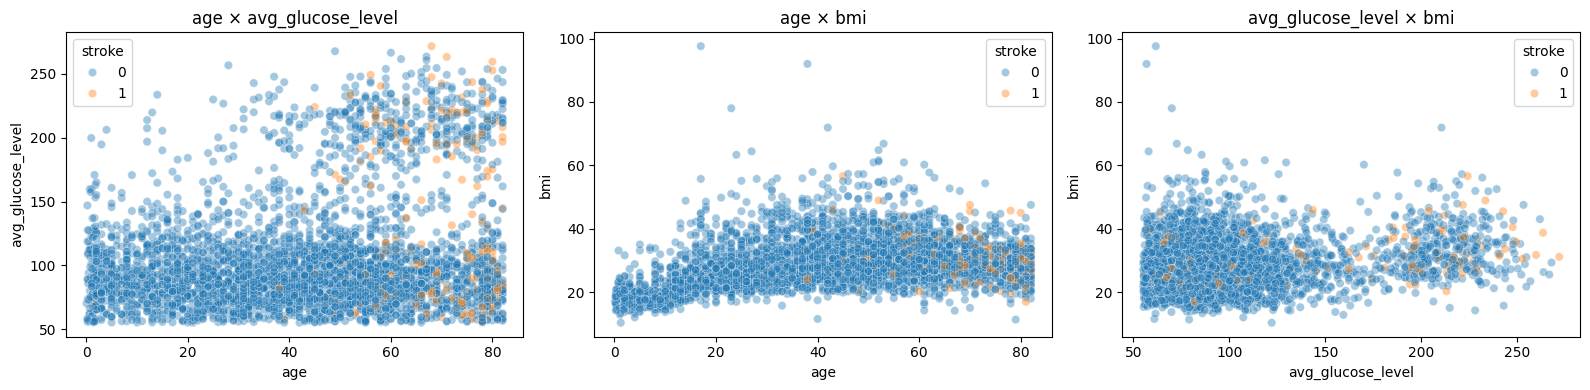

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=train, x='age', y='avg_glucose_level',
                hue='stroke', alpha=0.4, ax=axes[0])
sns.scatterplot(data=train, x='age', y='bmi',
                hue='stroke', alpha=0.4, ax=axes[1])
sns.scatterplot(data=train, x='avg_glucose_level', y='bmi',
                hue='stroke', alpha=0.4, ax=axes[2])
for ax in axes:
    ax.set_title(ax.get_xlabel() + ' × ' + ax.get_ylabel())
plt.tight_layout()
plt.show()

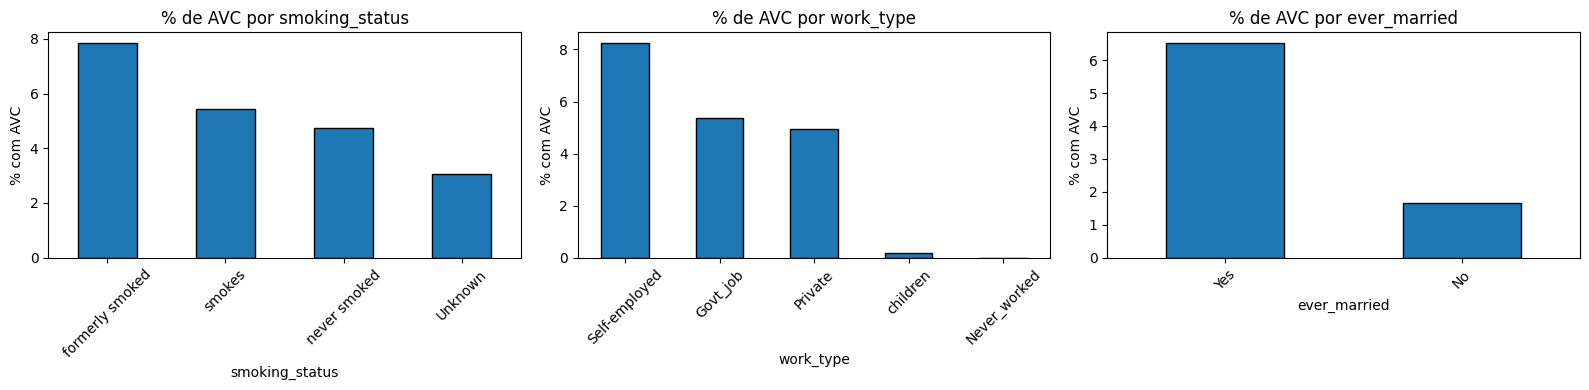

stroke,0,1
smoking_status,,
Unknown,0.970,0.030
formerly smoked,0.922,0.078
never smoked,0.953,0.047
smokes,0.946,0.054


In [ ]:
cats_alvo = ['smoking_status', 'work_type', 'ever_married']  # escolha 3

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, cats_alvo):
    taxa = (train.groupby(col)['stroke'].mean() * 100).sort_values(ascending=False)
    taxa.plot(kind='bar', ax=ax, edgecolor='black')
    ax.set_title(f'% de AVC por {col}')
    ax.set_ylabel('% com AVC')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Versão em tabela de contingência (proporção por linha)
pd.crosstab(train['smoking_status'], train['stroke'], normalize='index').round(3)

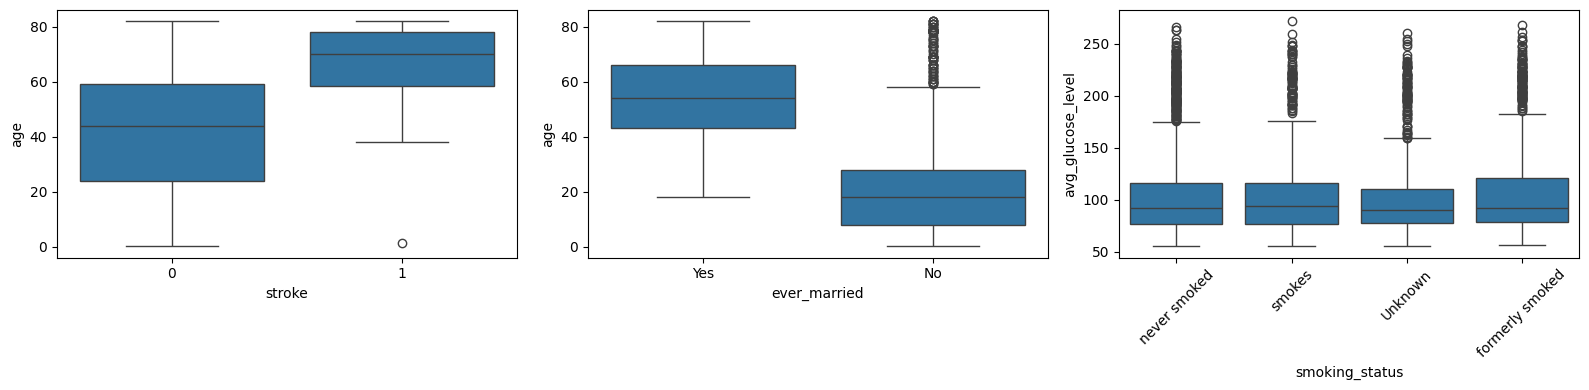

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=train, x='stroke', y='age', ax=axes[0])
sns.boxplot(data=train, x='ever_married', y='age', ax=axes[1])
sns.boxplot(data=train, x='smoking_status', y='avg_glucose_level', ax=axes[2])
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Pré-processamento dos Dados para Clustering

Vamos preparar os dados para o clustering, tratando valores inconsistentes, nulos, e aplicando transformações necessárias como codificação e escalonamento.

In [ ]:
# LIDANDO COM CATEGORIAS IRREGULARES

# 1. Coluna 'gender': Substituir 'Other' pela categoria mais frequente ('Female')
# Verificamos que 'Other' tem apenas 1 ocorrência.
# Antes de substituir, vamos verificar a contagem atual.
print("Contagem de 'gender' antes da correção:")
display(X['gender'].value_counts())

X['gender'] = X['gender'].replace('Other', 'Female')

print("\nContagem de 'gender' depois da correção:")
display(X['gender'].value_counts())

# 2. Coluna 'smoking_status': 'Unknown' será tratado como uma categoria separada
# mas é importante estar ciente de sua alta incidência.
# Não faremos alteração direta aqui, mas a codificação One-Hot cuidará disso.

Contagem de 'gender' antes da correção:


,count
gender,
Female,2994
Male,2115
Other,1



Contagem de 'gender' depois da correção:


,count
gender,
Female,2995
Male,2115


### Imputação de Valores Nulos (NaN) para `bmi`

A coluna `bmi` possui valores nulos. Vamos preenchê-los com a mediana da coluna, que é mais robusta a outliers do que a média.

In [ ]:
from sklearn.impute import SimpleImputer

# Cria uma cópia de X para não modificar o DataFrame original diretamente antes de todas as etapas
X_processed = X.copy()

# Imputação da mediana para 'bmi'
imputer_bmi = SimpleImputer(strategy='median')
X_processed['bmi'] = imputer_bmi.fit_transform(X_processed[['bmi']])

print("Valores nulos em 'bmi' após imputação:")
display(X_processed['bmi'].isnull().sum())

Valores nulos em 'bmi' após imputação:


np.int64(0)

### Codificação de Variáveis Categóricas e Escalonamento de Variáveis Numéricas

Utilizaremos `OneHotEncoder` para as variáveis categóricas e `StandardScaler` para as variáveis numéricas. Para organizar essas transformações, construiremos um `ColumnTransformer`.

In [ ]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identifica colunas numéricas e categóricas para o pré-processamento
# 'id' já foi removido de X

# Certifique-se de que 'colunas_numericas' e 'colunas_categoricas' refletem o DataFrame X_processed
# e não incluem o target 'stroke' se ainda estivesse lá.

# Atualiza as listas de colunas com base no X_processed após a imputação de BMI
# Excluímos 'id' e 'stroke' que já foram separados

# colunas_numericas = ['age', 'avg_glucose_level', 'bmi', 'hypertension', 'heart_disease']
# colunas_categoricas = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

# Re-obtem as listas de colunas de X_processed
# Removendo 'id' se ainda estivesse, embora já deva ter sido removido
num_features = X_processed.select_dtypes(include=['number']).columns.tolist()
cat_features = X_processed.select_dtypes(include=['object']).columns.tolist()

# Cria o ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)
    ])

# Aplica as transformações
X_scaled_encoded = preprocessor.fit_transform(X_processed)

print("Formato dos dados após codificação e escalonamento:", X_scaled_encoded.shape)

Formato dos dados após codificação e escalonamento: (5110, 20)


### Análise de Componentes Principais (PCA)

Para reduzir a dimensionalidade e facilitar o clustering, vamos aplicar PCA nos dados pré-processados. Isso pode ajudar a remover ruído e focar nas características mais importantes.

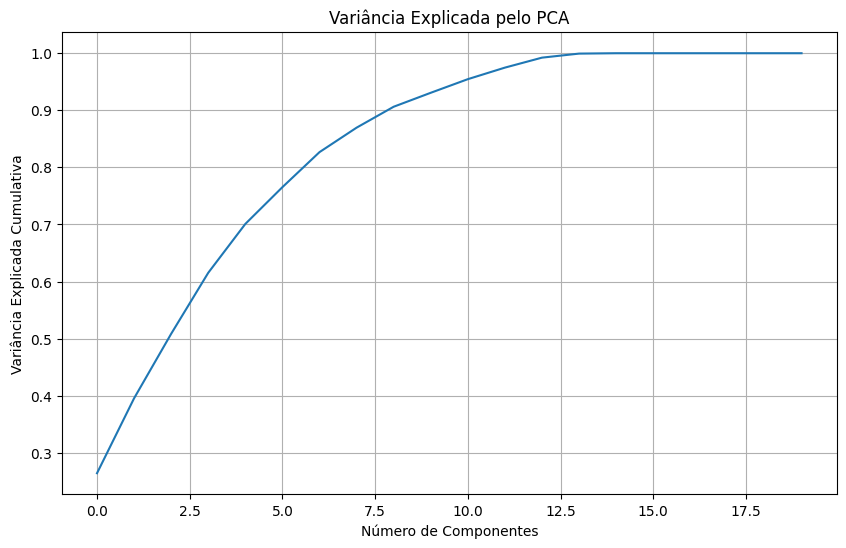

Formato dos dados após PCA com 10 componentes: (5110, 10)


In [ ]:
import numpy as np
from sklearn.decomposition import PCA

# Determinar o número ideal de componentes pode ser feito com uma curva de variância explicada
pca = PCA().fit(X_scaled_encoded)

plt.figure(figsize=(10, 6))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Número de Componentes')
plt.ylabel('Variância Explicada Cumulativa')
plt.title('Variância Explicada pelo PCA')
plt.grid(True)
plt.show()

# Vamos escolher um número de componentes que explique uma alta porcentagem da variância (ex: 95%)
# ou um número razoável para a visualização/interpretação.
# Para fins de exemplo, vamos começar com 10 componentes, mas o ideal seria analisar o gráfico.

n_components = 10 # Ajuste baseado na análise do gráfico acima
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled_encoded)

print(f"Formato dos dados após PCA com {n_components} componentes: {X_pca.shape}")

## Determinando o Número Ótimo de Clusters (k)

Utilizaremos dois métodos populares para encontrar o `k` ideal para o K-Means: o Método do Cotovelo (Elbow Method) e o Coeficiente de Silhueta (Silhouette Score).

Vamos começar importando as bibliotecas necessárias.

In [ ]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Definir um intervalo de k para testar
k_range = range(2, 11) # Geralmente testamos de 2 até um número razoável de clusters

# Armazenar os resultados para o Método do Cotovelo
sum_of_squared_distances = []

# Armazenar os resultados para o Coeficiente de Silhueta
silhouette_scores = []

# Executar K-Means para cada valor de k e calcular as métricas
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
    # !!! Alterado para usar X_scaled_encoded diretamente !!!
    kmeans.fit(X_scaled_encoded)
    sum_of_squared_distances.append(kmeans.inertia_)

    # Calcula o coeficiente de silhueta, mas apenas se houver mais de um cluster e mais de 1 amostra
    if k > 1:
        labels = kmeans.labels_
        # !!! Alterado para usar X_scaled_encoded para o silhouette_score !!!
        sil_avg = silhouette_score(X_scaled_encoded, labels)
        silhouette_scores.append(sil_avg)
    else:
        silhouette_scores.append(np.nan) # Para k=1, silhouette score não é aplicável

print("Cálculos para Elbow e Silhouette Methods concluídos usando X_scaled_encoded.")

Cálculos para Elbow e Silhouette Methods concluídos usando X_scaled_encoded.


### Método do Cotovelo (Elbow Method)

Este método procura um 'cotovelo' na curva da Soma dos Quadrados das Distâncias (SSD) para identificar o `k` ótimo. Um cotovelo indica que adicionar mais clusters não melhora substancialmente a dispersão dentro do cluster.

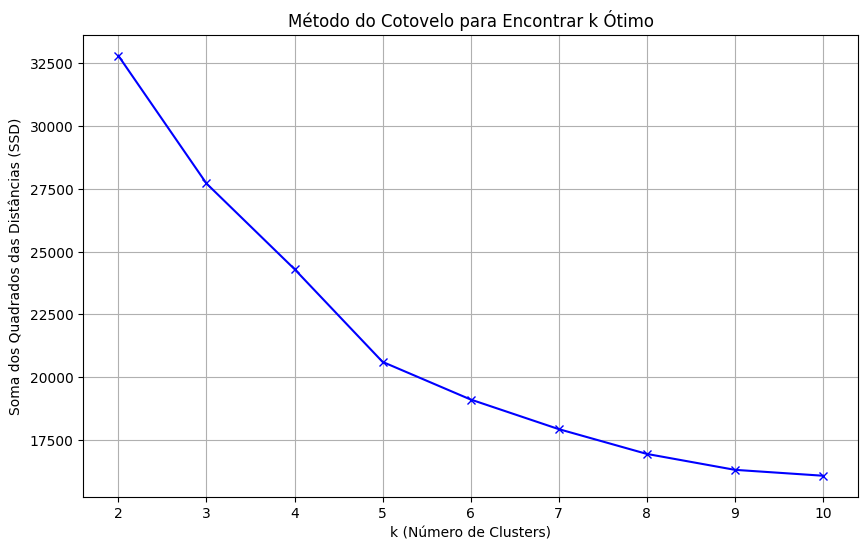

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k_range, sum_of_squared_distances, 'bx-')
plt.xlabel('k (Número de Clusters)')
plt.ylabel('Soma dos Quadrados das Distâncias (SSD)')
plt.title('Método do Cotovelo para Encontrar k Ótimo')
plt.xticks(k_range)
plt.grid(True)
plt.show()

### Coeficiente de Silhueta (Silhouette Method)

O coeficiente de silhueta mede quão bem um objeto se encaixa em seu próprio cluster (coesão) em comparação com outros clusters (separação). Um valor próximo de 1 indica que o objeto está bem correspondido ao seu próprio cluster e mal correspondido aos clusters vizinhos. Um valor próximo de -1 indica o oposto. Valores próximos de 0 indicam clusters sobrepostos.

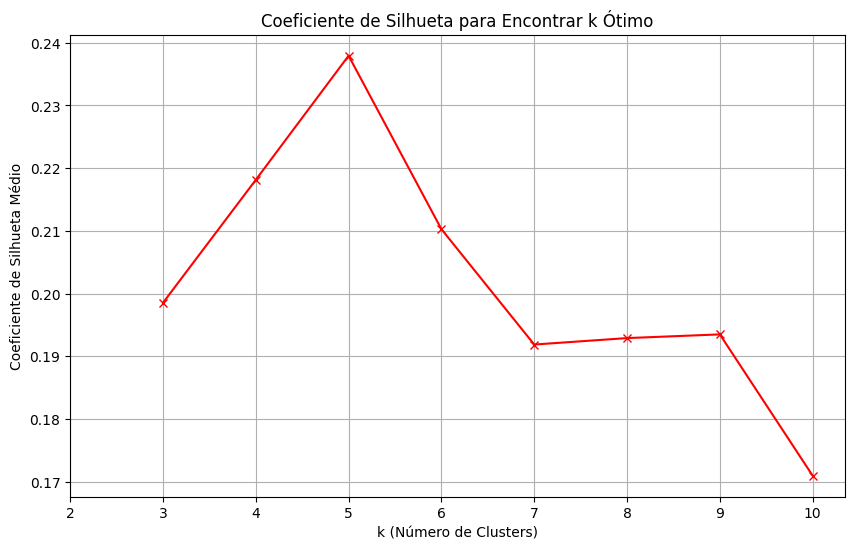

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(k_range[1:], silhouette_scores[1:], 'rx-') # k=1 não tem silhouette score
plt.xlabel('k (Número de Clusters)')
plt.ylabel('Coeficiente de Silhueta Médio')
plt.title('Coeficiente de Silhueta para Encontrar k Ótimo')
plt.xticks(k_range)
plt.grid(True)
plt.show()

Com base nos gráficos acima, você pode analisar e escolher o valor de `k` que melhor se adequa aos seus dados. O método do cotovelo busca o ponto onde a curva se 'dobra' mais acentuadamente, enquanto o coeficiente de silhueta busca o valor mais alto.

## Aplicação do K-Means com k = 5 e Visualização dos Clusters

Com base na análise anterior, vamos aplicar o algoritmo K-Means com `k=5` e visualizar os resultados dos clusters usando os dois primeiros componentes principais.

K-Means com 5 clusters aplicado a X_scaled_encoded. Rótulos de cluster gerados.


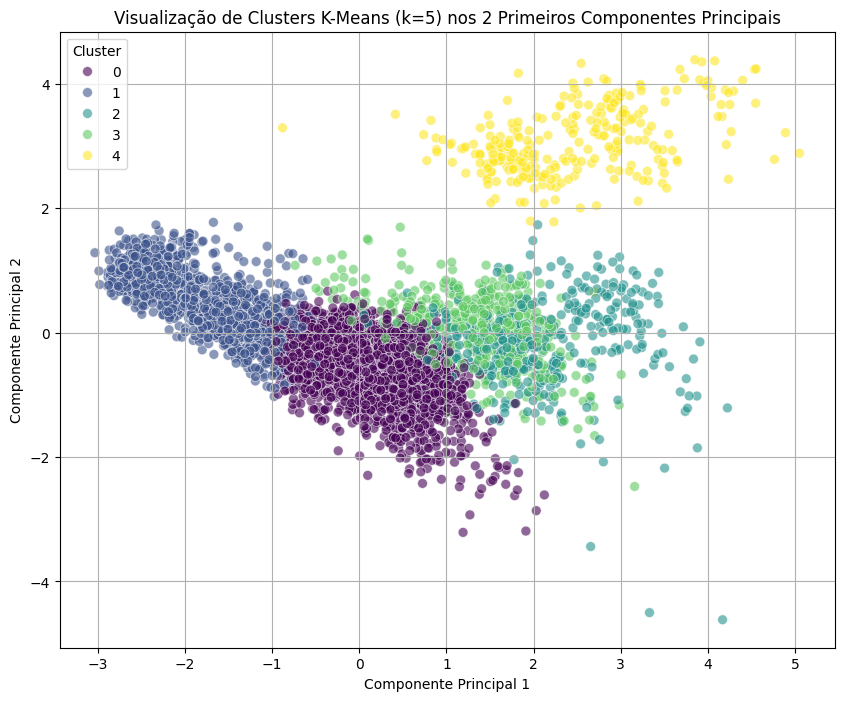

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Aplicar K-Means com o k escolhido (k=5) nos dados X_scaled_encoded
k_chosen = 5

kmeans_model = KMeans(n_clusters=k_chosen, random_state=42, n_init='auto')
cluster_labels = kmeans_model.fit_predict(X_scaled_encoded)

print(f"K-Means com {k_chosen} clusters aplicado a X_scaled_encoded. Rótulos de cluster gerados.")

# Criar um novo PCA com 2 componentes APENAS para visualização
pca_for_viz = PCA(n_components=2)
X_pca_2d = pca_for_viz.fit_transform(X_scaled_encoded)

# Visualizar os clusters usando os dois primeiros componentes principais do PCA_for_viz
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x=X_pca_2d[:, 0], # Primeiro componente principal para visualização
    y=X_pca_2d[:, 1], # Segundo componente principal para visualização
    hue=cluster_labels, # Cor por rótulo de cluster do K-Means em X_scaled_encoded
    palette='viridis', # Escolha de paleta de cores
    s=50, # Tamanho dos pontos
    alpha=0.6 # Transparência
)
plt.title(f'Visualização de Clusters K-Means (k={k_chosen}) nos 2 Primeiros Componentes Principais')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

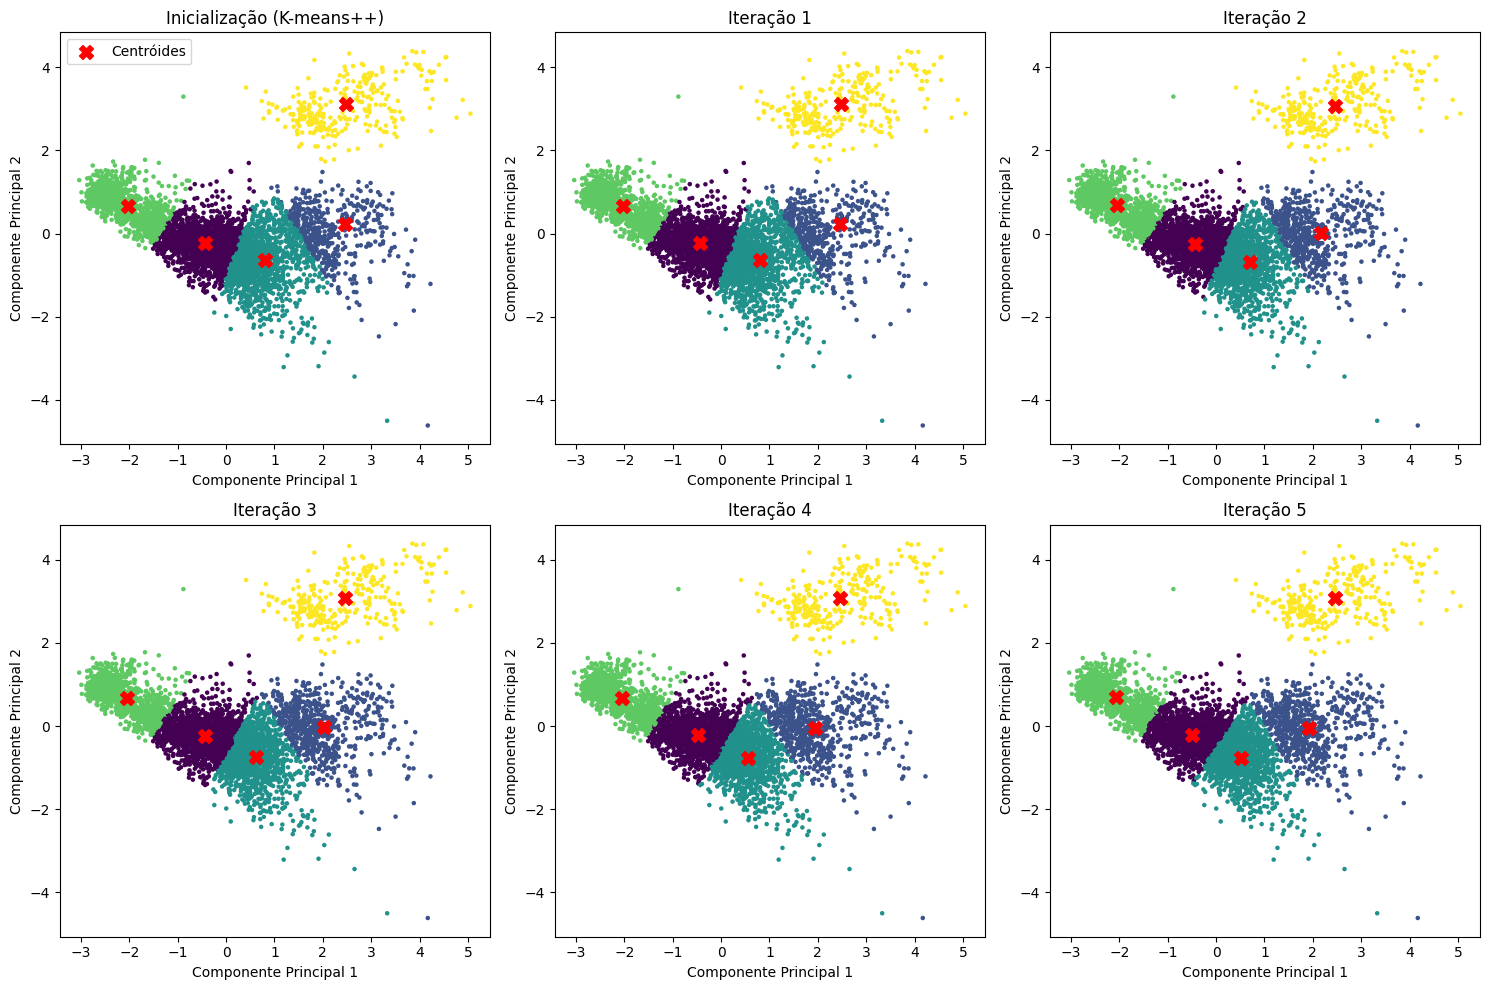

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans

# Usamos X_pca_2d para visualizar os clusters, pois ele já é uma representação 2D
X_display = X_pca_2d
k = k_chosen # Usar o k_chosen atual (que é 3)

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
axs = axs.flatten() # Achata o array de subplots para facilitar a iteração

ax_initial = axs[0]
ax_initial.set_title("Inicialização (K-means++)")
# Para a visualização inicial, podemos rodar o kmeans com 1 iteração e pegar os centros
kmeans_initial = KMeans(n_clusters=k, random_state=42, n_init=1, max_iter=1).fit(X_display)
y_initial = kmeans_initial.labels_
ax_initial.scatter(X_display[:, 0], X_display[:, 1], c=y_initial, s=5, cmap='viridis')
ax_initial.scatter(kmeans_initial.cluster_centers_[:, 0], kmeans_initial.cluster_centers_[:, 1], c="red", marker='X', s=100, label='Centróides')
ax_initial.legend()
ax_initial.set_xlabel('Componente Principal 1')
ax_initial.set_ylabel('Componente Principal 2')


max_it = 5 # Número de iterações para visualizar

for it in range(1, max_it + 1):
    # Rodar K-Means com o número de iterações crescente
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=1, # Para cada subplot, uma nova inicialização é feita (ou poderia ser 'auto' para o melhor resultado)
        max_iter=it,
        init='k-means++' # Explicitamente usando k-means++ para inicialização inteligente
    ).fit(X_display)

    y = kmeans.labels_
    ax = axs[it] # Próximo subplot
    ax.set_title(f'Iteração {it}')
    ax.scatter(X_display[:, 0], X_display[:, 1], c=y, s=5, cmap='viridis')
    ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="red", marker='X', s=100)
    ax.set_xlabel('Componente Principal 1')
    ax.set_ylabel('Componente Principal 2')

# Desabilitar eixos para subplots não utilizados, se houver
for i in range(max_it + 1, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.show()

### Análise dos Componentes Principais: O que significam?

In [ ]:
import pandas as pd
from sklearn.decomposition import PCA

# Obter os nomes das features após o pré-processamento (escalonamento e one-hot encoding)
feature_names = preprocessor.get_feature_names_out()

# Criar um NOVO PCA com 2 componentes para interpretar os eixos da visualização
pca_interpretation = PCA(n_components=2)
pca_interpretation.fit(X_scaled_encoded)

# Criar um DataFrame para os loadings dos componentes principais
# pca_interpretation.components_ contém os loadings. Cada linha é um componente principal,
# e cada coluna corresponde a uma feature original (após pré-processamento).
loadings_df = pd.DataFrame(
    pca_interpretation.components_,
    columns=feature_names
)

print("Loadings (contribuições das features originais) para os Componentes Principais:")
# Vamos mostrar as contribuições para os dois primeiros componentes principais
display(loadings_df.head(2))

# Para uma análise mais clara, vamos identificar as features com maiores pesos (positivos e negativos)
# para o Componente Principal 1 e Componente Principal 2.

print("\n--- Top 5 Features Positivas e Negativas para o Componente Principal 1 ---")
cp1_loadings = loadings_df.iloc[0].sort_values(ascending=False)
display(pd.concat([cp1_loadings.head(5), cp1_loadings.tail(5)]))

print("\n--- Top 5 Features Positivas e Negativas para o Componente Principal 2 ---")
cp2_loadings = loadings_df.iloc[1].sort_values(ascending=False)
display(pd.concat([cp2_loadings.head(5), cp2_loadings.tail(5)]))

print("\nCom base nesta análise, podemos interpretar que:")
# Interpretação baseada nos loadings do PCA de 2 componentes para visualização
# O Componente Principal 1 (eixo X) é predominantemente influenciado por:
cp1_positive_features = ', '.join(cp1_loadings.head(3).index.str.replace('num__', '').str.replace('cat__', ''))
cp1_negative_features = ', '.join(cp1_loadings.tail(3).index.str.replace('num__', '').str.replace('cat__', ''))
print(f"- O Componente Principal 1 (eixo X) é predominantemente influenciado positivamente por: {cp1_positive_features}. E negativamente por: {cp1_negative_features}.")

# O Componente Principal 2 (eixo Y) é predominantemente influenciado por:
cp2_positive_features = ', '.join(cp2_loadings.head(3).index.str.replace('num__', '').str.replace('cat__', ''))
cp2_negative_features = ', '.join(cp2_loadings.tail(3).index.str.replace('num__', '').str.replace('cat__', ''))
print(f"- O Componente Principal 2 (eixo Y) é predominantemente influenciado positivamente por: {cp2_positive_features}. E negativamente por: {cp2_negative_features}.")

Loadings (contribuições das features originais) para os Componentes Principais:


,num__age,num__hypertension,num__heart_disease,num__avg_glucose_level,num__bmi,cat__gender_Female,cat__gender_Male,cat__ever_married_No,cat__ever_married_Yes,cat__work_type_Govt_job,cat__work_type_Never_worked,cat__work_type_Private,cat__work_type_Self-employed,cat__work_type_children,cat__Residence_type_Rural,cat__Residence_type_Urban,cat__smoking_status_Unknown,cat__smoking_status_formerly smoked,cat__smoking_status_never smoked,cat__smoking_status_smokes
0,0.583288,0.356899,0.286230,0.347692,0.416884,-0.001946,0.001946,-0.221948,0.221948,0.025391,-0.003086,0.058514,0.067234,-0.148053,-0.001842,0.001842,-0.140079,0.059733,0.052748,0.027598
1,-0.078165,0.095240,0.720345,0.325602,-0.525963,-0.102970,0.102970,0.109663,-0.109663,-0.018275,0.001014,-0.102466,0.009457,0.110269,0.000873,-0.000873,0.095188,-0.007477,-0.075193,-0.012519



--- Top 5 Features Positivas e Negativas para o Componente Principal 1 ---


,0
num__age,0.583288
num__bmi,0.416884
num__hypertension,0.356899
num__avg_glucose_level,0.347692
num__heart_disease,0.286230
cat__gender_Female,-0.001946
cat__work_type_Never_worked,-0.003086
cat__smoking_status_Unknown,-0.140079
cat__work_type_children,-0.148053
cat__ever_married_No,-0.221948



--- Top 5 Features Positivas e Negativas para o Componente Principal 2 ---


,1
num__heart_disease,0.720345
num__avg_glucose_level,0.325602
cat__work_type_children,0.110269
cat__ever_married_No,0.109663
cat__gender_Male,0.102970
num__age,-0.078165
cat__work_type_Private,-0.102466
cat__gender_Female,-0.102970
cat__ever_married_Yes,-0.109663
num__bmi,-0.525963



Com base nesta análise, podemos interpretar que:
- O Componente Principal 1 (eixo X) é predominantemente influenciado positivamente por: age, bmi, hypertension. E negativamente por: smoking_status_Unknown, work_type_children, ever_married_No.
- O Componente Principal 2 (eixo Y) é predominantemente influenciado positivamente por: heart_disease, avg_glucose_level, work_type_children. E negativamente por: gender_Female, ever_married_Yes, bmi.
